# F7: P5 on the full E5 — how the investor mix and herding change the propagation of real shocks

**Question P5:** how do the strategies of the investors and herding change the way shocks travel through the
dependency graph? Experiment E5 (`configs/f6_e5.yaml`): the 18-company market of `real_v1` on the real commodity
and S&P 500 series of 2024–2025, 502 sessions; investor mix {`mixed`, `network`, `trend`} × herding
h {0, 0.2, 0.4} × 30 seeds (3001–3030) = 270 runs. E4 (`notebooks/05_chain_wave.ipynb`) answered the same question
on the three-company chain with a synthetic oil step; here the shocks are the real moves of two years.

**Mixes** (shares of the 500 investors: myopic valuers / network valuers / trend followers / noise): `mixed`
30/30/20/20, `network` 15/45/20/20, `trend` 35/15/30/20; plus 25 rebalancing funds in every run.

**Metrics, one value per run** (after the 10 warmup sessions; "R" is the reference path the run logged):

| Group | Metric | Meaning |
|---|---|---|
| speed | `day0`, `day1` | pooled OLS of the daily return of every company on the change of its own R the same day and the day before; 1 and 0 for a market that prices the graph at once |
| speed | `day1_d1`, `day1_d2`, `day1_d3` | the same `day1` for the companies 1, 2 and 3 links from oil (COP, EOG / VLO, MPC / DAL, UAL, ODFL) |
| speed | `lag` (D1) | `marketsim.metrics.wave_metrics`: shift with the largest cross-correlation of Δ ln R and Δ ln P on a 0.25-session grid, up to 3 sessions; mean over the 18 companies |
| size | `vol_amp` (D1) | `wave_metrics`: σ(Δ ln P) / σ(Δ ln R) per session; median over companies (> 1: the market amplifies the moves of R) |
| accuracy | `corr_R` | correlation of daily returns of P and R, median over companies |
| accuracy | `gap_days` | company-days with \|ln P/R\| > 10% (of ~8900 per run) |
| inertia | `acf1` | lag-1 autocorrelation of daily returns, mean over companies (real stocks: −0.05) |
| stability | `collapse` | some company's close fell below half of its R (or rose above twice it) at least once |

**Statistics.** The unit is the run. Contrasts are **paired by seed** (the same seed in two cells; seeds 3001–3030
in every cell): the difference of a metric between two cells per seed, its mean, and a 95% interval from a
bootstrap over seeds (5000 draws). A pair is dropped if either run collapsed; collapses are reported separately,
as their own outcome, with Wilson intervals. There are 12 contrasts per metric (composition: network − mixed and
trend − mixed at each h; herding: h = 0.2 − 0 and 0.4 − 0 in each mix), so the table also marks contrasts whose
interval at the Bonferroni level 1 − 0.05/12 excludes zero.


In [1]:
import math
import multiprocessing as mp
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from marketsim.metrics import as_of, price_series, reference_series, wave_metrics
from marketsim.sim.log_schema import load_run

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
E5 = ROOT / "runs" / "f6" / "v1" / "e5"
WARMUP = 10
DISTANCE = {"d1": ["COP", "EOG"], "d2": ["VLO", "MPC"], "d3": ["DAL", "UAL", "ODFL"]}
MIXES, HS = ["mixed", "network", "trend"], [0.0, 0.2, 0.4]
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)
summary = pd.read_csv(E5 / "summary.csv")
print(len(summary), "runs;", summary.groupby(["agents.composition", "agents.herding.h"]).size().unique(), "per cell")


270 runs; [30] per cell


In [2]:
def ols_day0_day1(r, q):
    # Pooled OLS (with intercept) of returns r on the same-day and previous-day change of R (q); arrays day x company.
    y, x0, x1 = r[1:].ravel(), q[1:].ravel(), q[:-1].ravel()
    ok = np.isfinite(y) & np.isfinite(x0) & np.isfinite(x1)
    beta = np.linalg.lstsq(np.column_stack([np.ones(ok.sum()), x0[ok], x1[ok]]), y[ok], rcond=None)[0]
    return beta[1], beta[2]


def run_metrics(run_id):
    log = load_run(E5 / run_id)
    tickers = log.meta["assets"]
    n = log.meta["config"]["n_sessions"]
    ends = np.arange(n) + 1 - 1e-9          # the last snapshot of every session
    P = np.column_stack([as_of(price_series(log, a), ends) for a in range(len(tickers))])
    R = np.column_stack([as_of(reference_series(log, a), ends) for a in range(len(tickers))])
    P, R = pd.DataFrame(P, columns=tickers).ffill(), pd.DataFrame(R, columns=tickers)
    gap = np.log(P / R).iloc[WARMUP:]
    r, q = np.log(P).diff().iloc[WARMUP + 1:], np.log(R).diff().iloc[WARMUP + 1:]
    out = {"run_id": run_id}
    out["day0"], out["day1"] = ols_day0_day1(r.to_numpy(), q.to_numpy())
    for name, members in DISTANCE.items():
        out[f"day0_{name}"], out[f"day1_{name}"] = ols_day0_day1(r[members].to_numpy(), q[members].to_numpy())
    wave = [wave_metrics(log, a, t0=float(WARMUP), step=0.25, max_lag=12) for a in range(len(tickers))]
    out["lag"] = float(np.nanmean([w["lag_sessions"] for w in wave]))
    out["vol_amp"] = float(np.nanmedian([w["volatility_amplification"] for w in wave]))
    out["corr_R"] = float(r.corrwith(q).median())
    out["gap_days"] = int((gap.abs() > 0.10).to_numpy().sum())
    out["acf1"] = float(np.mean([r[t].autocorr(1) for t in tickers]))
    out["worst_gap"] = float(gap.abs().to_numpy().max())
    out["collapse"] = bool(out["worst_gap"] > math.log(2))
    return out


cache = E5 / "p5_metrics.csv"
known = pd.read_csv(cache) if cache.exists() else pd.DataFrame(columns=["run_id"])
missing = [r for r in summary.run_id if r not in set(known.run_id)]
if missing:   # ~0.5 s per run; "fork" lets the workers use the functions defined in this notebook
    with mp.get_context("fork").Pool(8) as pool:
        known = pd.concat([known, pd.DataFrame(pool.map(run_metrics, missing))], ignore_index=True)
    known.to_csv(cache, index=False)
runs = summary[["run_id", "seed", "agents.composition", "agents.herding.h"]].rename(
    columns={"agents.composition": "mix", "agents.herding.h": "h"}).merge(known, on="run_id")
runs["collapse"] = runs["collapse"].astype(bool)
METRICS = ["day0", "day1", "day1_d1", "day1_d2", "day1_d3", "lag", "vol_amp", "corr_R", "gap_days", "acf1"]
print(len(runs), "runs with metrics")


270 runs with metrics


## 1. The cells

Means over the runs of a cell without collapses (standard error over seeds in the second table).


In [3]:
ok = runs.loc[~runs.collapse]
cell = ok.groupby(["mix", "h"])[METRICS].mean()
se = ok.groupby(["mix", "h"])[METRICS].sem()
display(cell.round(3))
se.round(3)


day0   day1  day1_d1  day1_d2  day1_d3    lag  vol_amp  corr_R  gap_days   acf1
mix     h                                                                                    
mixed   0.0  1.036  0.191   -0.031    0.243    0.160  0.574    1.336   0.824    10.233 -0.011
        0.2  1.040  0.184   -0.076    0.243    0.144  0.649    1.395   0.802    17.200 -0.050
        0.4  0.963  0.245   -0.029    0.373    0.214  0.720    1.463   0.708    35.833 -0.076
network 0.0  1.033  0.197   -0.043    0.334    0.169  0.595    1.341   0.817    10.633 -0.011
        0.2  1.033  0.197   -0.088    0.371    0.163  0.655    1.409   0.788    19.000 -0.052
        0.4  0.954  0.259   -0.042    0.533    0.230  0.725    1.494   0.696    37.300 -0.083
trend   0.0  0.930  0.377    0.196    0.429    0.387  0.635    1.532   0.669   138.767  0.177
        0.2  0.915  0.394    0.183    0.475    0.395  0.701    1.617   0.623   186.000  0.164
        0.4  0.828  0.435    0.276    0.545    0.454  0.776    1.729   0.524   256.107  0.150

day0   day1  day1_d1  day1_d2  day1_d3    lag  vol_amp  corr_R  gap_days   acf1
mix     h                                                                                    
mixed   0.0  0.004  0.004    0.013    0.017    0.014  0.004    0.005   0.004     2.149  0.003
        0.2  0.004  0.004    0.015    0.020    0.017  0.006    0.004   0.004     3.119  0.003
        0.4  0.004  0.005    0.019    0.022    0.016  0.005    0.008   0.005     4.903  0.003
network 0.0  0.004  0.004    0.013    0.018    0.014  0.005    0.005   0.004     2.397  0.003
        0.2  0.003  0.004    0.015    0.024    0.017  0.005    0.006   0.003     3.855  0.003
        0.4  0.004  0.004    0.018    0.023    0.016  0.004    0.009   0.005     5.848  0.002
trend   0.0  0.005  0.006    0.023    0.021    0.013  0.007    0.010   0.006    17.750  0.003
        0.2  0.006  0.007    0.025    0.024    0.016  0.009    0.011   0.006    18.709  0.004
        0.4  0.007  0.006    0.026    0.022    0.015  0.009    0.014   0.005    16.935  0.004

In [4]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, centre - half), min(1.0, centre + half)


rows = []
for (mix, h), g in runs.groupby(["mix", "h"]):
    k, n = int(g.collapse.sum()), len(g)
    lo, hi = wilson(k, n)
    rows.append({"mix": mix, "h": h, "collapsed": k, "runs": n, "rate": k / n, "95% lo": lo, "95% hi": hi})
collapses = pd.DataFrame(rows).set_index(["mix", "h"])
display(collapses.round(3))


def fisher_greater(a, n1, b, n2):
    # One-sided Fisher exact test: is the collapse rate of group 1 (a of n1) higher than of group 2 (b of n2)?
    total, k = n1 + n2, a + b
    def p(x):
        return math.comb(n1, x) * math.comb(n2, k - x) / math.comb(total, k)
    return sum(p(x) for x in range(a, min(n1, k) + 1))


trend_herd = runs.loc[(runs.mix == "trend") & (runs.h > 0)]
rest = runs.drop(trend_herd.index)
a, n1, b, n2 = int(trend_herd.collapse.sum()), len(trend_herd), int(rest.collapse.sum()), len(rest)
print(f"trend with herding: {a} of {n1} collapsed, 95% {wilson(a, n1)[0]:.3f}-{wilson(a, n1)[1]:.3f}; "
      f"all other cells: {b} of {n2}, 95% {wilson(b, n2)[0]:.3f}-{wilson(b, n2)[1]:.3f}; "
      f"Fisher exact one-sided p = {fisher_greater(a, n1, b, n2):.1e}")


collapsed  runs   rate  95% lo  95% hi
mix     h                                          
mixed   0.0          0    30  0.000   0.000   0.114
        0.2          0    30  0.000   0.000   0.114
        0.4          0    30  0.000   0.000   0.114
network 0.0          0    30  0.000   0.000   0.114
        0.2          0    30  0.000   0.000   0.114
        0.4          0    30  0.000   0.000   0.114
trend   0.0          0    30  0.000   0.000   0.114
        0.2          4    30  0.133   0.053   0.297
        0.4          2    30  0.067   0.018   0.213

trend with herding: 6 of 60 collapsed, 95% 0.047-0.201; all other cells: 0 of 210, 95% 0.000-0.018; Fisher exact one-sided p = 9.8e-05


## 2. Paired contrasts

Every contrast is "cell A − cell B" on the same seeds. `clear`: the 95% interval excludes 0; `clear (Bonferroni)`:
the interval at 1 − 0.05/12 excludes 0.


In [5]:
LEVEL = 1 - 0.05 / 12


def paired(a, b, metric, rng, draws=5000):
    x = a.set_index("seed")[[metric, "collapse"]].join(b.set_index("seed")[[metric, "collapse"]],
                                                      lsuffix="_a", rsuffix="_b", how="inner")
    x = x.loc[~x.collapse_a & ~x.collapse_b]
    d = (x[metric + "_a"] - x[metric + "_b"]).to_numpy(dtype=float)
    boot = rng.choice(d, (draws, len(d))).mean(axis=1)
    lo, hi = np.quantile(boot, [0.025, 0.975])
    blo, bhi = np.quantile(boot, [(1 - LEVEL) / 2, 1 - (1 - LEVEL) / 2])
    return {"pairs": len(d), "mean": d.mean(), "ci_low": lo, "ci_high": hi, "clear": lo > 0 or hi < 0,
            "clear (Bonferroni)": blo > 0 or bhi < 0}


def contrasts(runs, metrics, seed=2026):
    rng = np.random.default_rng(seed)
    cellrun = {key: g for key, g in runs.groupby(["mix", "h"])}
    rows = []
    for metric in metrics:
        for h in HS:
            for mix in ("network", "trend"):
                rows.append({"metric": metric, "factor": "mix", "contrast": f"{mix} − mixed", "at": f"h={h}",
                             **paired(cellrun[(mix, h)], cellrun[("mixed", h)], metric, rng)})
        for mix in MIXES:
            for h in (0.2, 0.4):
                rows.append({"metric": metric, "factor": "herding", "contrast": f"h={h} − h=0", "at": mix,
                             **paired(cellrun[(mix, h)], cellrun[(mix, 0.0)], metric, rng)})
    return pd.DataFrame(rows)


C = contrasts(runs, METRICS)
C.to_csv(E5 / "p5_contrasts.csv", index=False)
C.loc[C.factor == "mix"].round(4)


,metric,factor,contrast,at,pairs,mean,ci_low,ci_high,clear,clear (Bonferroni)
0,day0,mix,network − mixed,h=0.0,30,-0.0036,-0.0110,0.0038,False,False
1,day0,mix,trend − mixed,h=0.0,30,-0.1063,-0.1175,-0.0957,True,True
2,day0,mix,network − mixed,h=0.2,30,-0.0067,-0.0158,0.0027,False,False
3,day0,mix,trend − mixed,h=0.2,26,-0.1237,-0.1377,-0.1100,True,True
4,day0,mix,network − mixed,h=0.4,30,-0.0090,-0.0180,0.0002,False,False
5,day0,mix,trend − mixed,h=0.4,28,-0.1347,-0.1499,-0.1208,True,True
12,day1,mix,network − mixed,h=0.0,30,0.0055,-0.0015,0.0129,False,False
13,day1,mix,trend − mixed,h=0.0,30,0.1857,0.1723,0.1974,True,True
14,day1,mix,network − mixed,h=0.2,30,0.0128,0.0026,0.0227,True,False
15,day1,mix,trend − mixed,h=0.2,26,0.2107,0.1964,0.2249,True,True


In [6]:
C.loc[C.factor == "herding"].round(4)


,metric,factor,contrast,at,pairs,mean,ci_low,ci_high,clear,clear (Bonferroni)
6,day0,herding,h=0.2 − h=0,mixed,30,0.0033,-0.0008,0.0072,False,False
7,day0,herding,h=0.4 − h=0,mixed,30,-0.0729,-0.0770,-0.0686,True,True
8,day0,herding,h=0.2 − h=0,network,30,0.0002,-0.0053,0.0056,False,False
9,day0,herding,h=0.4 − h=0,network,30,-0.0782,-0.0834,-0.0732,True,True
10,day0,herding,h=0.2 − h=0,trend,26,-0.0167,-0.0239,-0.0097,True,True
11,day0,herding,h=0.4 − h=0,trend,28,-0.1029,-0.1132,-0.0938,True,True
18,day1,herding,h=0.2 − h=0,mixed,30,-0.0071,-0.0115,-0.0029,True,True
19,day1,herding,h=0.4 − h=0,mixed,30,0.0539,0.0473,0.0604,True,True
20,day1,herding,h=0.2 − h=0,network,30,0.0003,-0.0055,0.0064,False,False
21,day1,herding,h=0.4 − h=0,network,30,0.0618,0.0555,0.0685,True,True


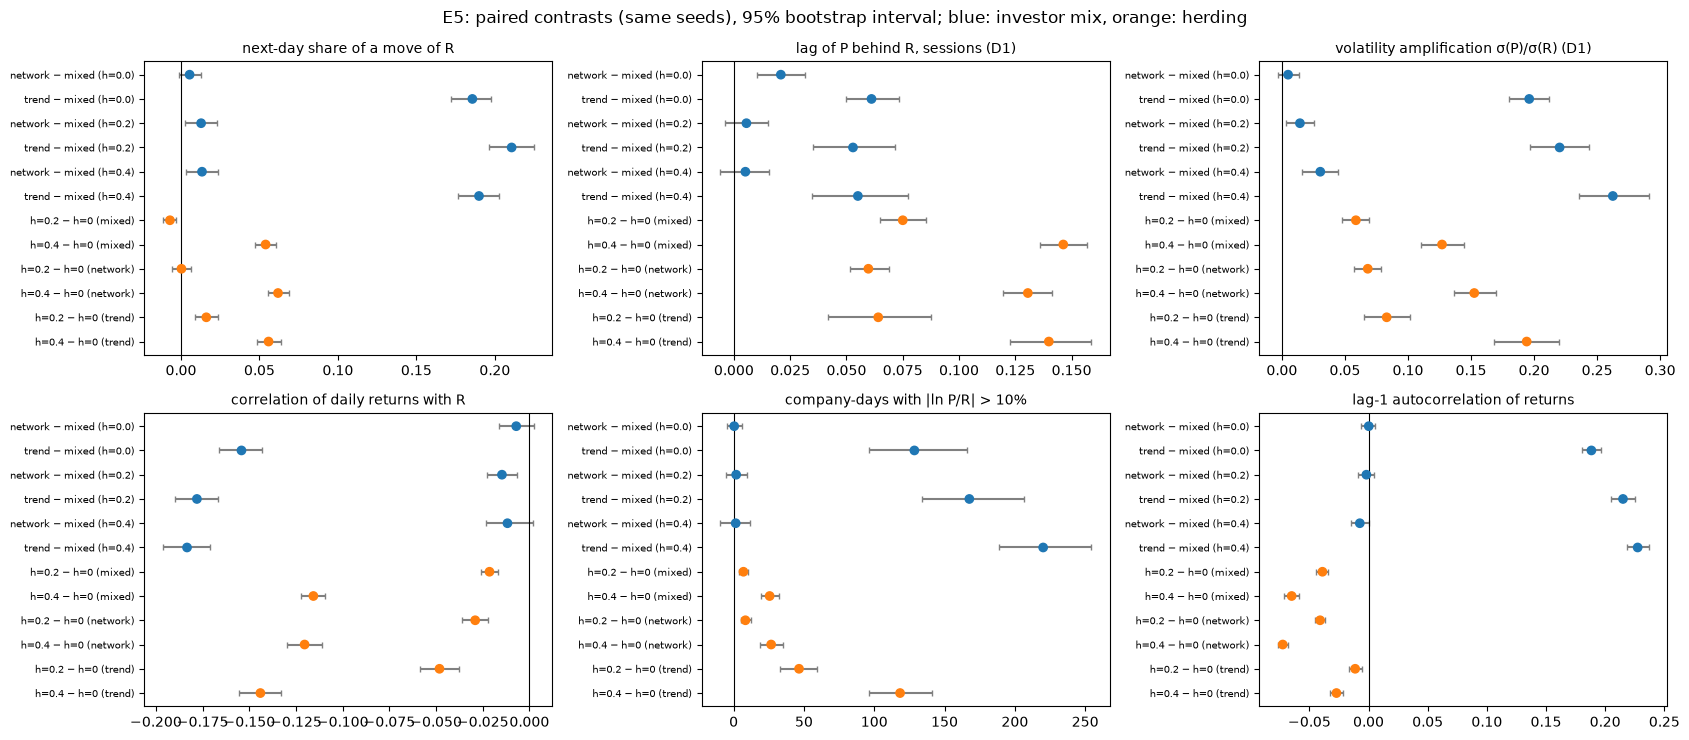

In [7]:
shown = [("day1", "next-day share of a move of R"), ("lag", "lag of P behind R, sessions (D1)"),
         ("vol_amp", "volatility amplification σ(P)/σ(R) (D1)"), ("corr_R", "correlation of daily returns with R"),
         ("gap_days", "company-days with |ln P/R| > 10%"), ("acf1", "lag-1 autocorrelation of returns")]
fig, axes = plt.subplots(2, 3, figsize=(17, 7.5))
for ax, (metric, title) in zip(axes.flat, shown):
    part = C.loc[C.metric == metric].reset_index(drop=True)
    y = np.arange(len(part))[::-1]
    colors = np.where(part.factor == "mix", "C0", "C1")
    ax.errorbar(part["mean"], y, xerr=[part["mean"] - part.ci_low, part.ci_high - part["mean"]], fmt="none",
                ecolor="grey", capsize=2)
    ax.scatter(part["mean"], y, c=colors, zorder=3)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(y, [f"{c} ({a})" for c, a in zip(part.contrast, part["at"])], fontsize=7)
    ax.set_title(title, fontsize=10)
fig.suptitle("E5: paired contrasts (same seeds), 95% bootstrap interval; blue: investor mix, orange: herding")
plt.tight_layout()
plt.show()


## 3. Does the network mix slow the second link, as on the chain (E4)?

On the chain, network valuers made VLO (two links from oil) slower than in the mixed composition and left COP
(one link) as it was. Here: the next-day share `day1` by distance from oil, network − mixed.


In [8]:
C.loc[(C.metric.isin(["day1_d1", "day1_d2", "day1_d3"])) & (C.factor == "mix")].round(4)


,metric,factor,contrast,at,pairs,mean,ci_low,ci_high,clear,clear (Bonferroni)
24,day1_d1,mix,network − mixed,h=0.0,30,-0.0121,-0.0359,0.0112,False,False
25,day1_d1,mix,trend − mixed,h=0.0,30,0.2268,0.1861,0.2684,True,True
26,day1_d1,mix,network − mixed,h=0.2,30,-0.0119,-0.0379,0.0162,False,False
27,day1_d1,mix,trend − mixed,h=0.2,26,0.2656,0.2254,0.3047,True,True
28,day1_d1,mix,network − mixed,h=0.4,30,-0.0131,-0.0487,0.0217,False,False
29,day1_d1,mix,trend − mixed,h=0.4,28,0.3118,0.2699,0.3556,True,True
36,day1_d2,mix,network − mixed,h=0.0,30,0.0917,0.0678,0.1145,True,True
37,day1_d2,mix,trend − mixed,h=0.0,30,0.1867,0.1523,0.2232,True,True
38,day1_d2,mix,network − mixed,h=0.2,30,0.1279,0.0916,0.1636,True,True
39,day1_d2,mix,trend − mixed,h=0.2,26,0.2324,0.1947,0.2727,True,True


## 4. Does the investor mix change the effect of herding? (interaction)

Difference in differences on the same seeds: (h = 0.4 − h = 0 in a mix) − (h = 0.4 − h = 0 in `mixed`). Positive
for `gap_days`: herding opens more gaps in that mix than in the mixed one.


In [9]:
def did(runs, mix, metric, rng, h=0.4, draws=5000):
    cell = {key: g.set_index("seed") for key, g in runs.groupby(["mix", "h"])}
    parts = [cell[(mix, h)], cell[(mix, 0.0)], cell[("mixed", h)], cell[("mixed", 0.0)]]
    keep = ~sum(p["collapse"].astype(int) for p in parts).astype(bool)
    keep = keep[keep].index
    d = ((parts[0][metric] - parts[1][metric]) - (parts[2][metric] - parts[3][metric])).loc[keep].to_numpy(float)
    boot = rng.choice(d, (draws, len(d))).mean(axis=1)
    lo, hi = np.quantile(boot, [0.025, 0.975])
    return {"mix": mix, "metric": metric, "seeds": len(d), "mean": d.mean(), "ci_low": lo, "ci_high": hi,
            "clear": lo > 0 or hi < 0}


rng = np.random.default_rng(7)
interaction = pd.DataFrame([did(runs, mix, m, rng) for mix in ("network", "trend")
                            for m in ("day1", "lag", "vol_amp", "corr_R", "gap_days", "acf1")])
interaction.round(4)


,mix,metric,seeds,mean,ci_low,ci_high,clear
0,network,day1,30,0.0079,-0.0003,0.0158,False
1,network,lag,30,-0.0157,-0.0310,-0.0009,True
2,network,vol_amp,30,0.0256,0.0094,0.0410,True
3,network,corr_R,30,-0.0047,-0.0161,0.0066,False
4,network,gap_days,30,1.0667,-6.1333,8.0008,False
5,network,acf1,30,-0.0076,-0.0155,0.0001,False
6,trend,day1,28,0.0037,-0.0059,0.0132,False
7,trend,lag,28,-0.0079,-0.0327,0.0164,False
8,trend,vol_amp,28,0.0643,0.0387,0.0899,True
9,trend,corr_R,28,-0.0278,-0.0421,-0.0149,True


## 5. What E5 says about P5

All numbers: paired differences on the same seeds, 95% bootstrap intervals; "clear" survives the Bonferroni level
unless said otherwise. Collapsed runs are left out of the contrasts and counted separately.

**Investor mix.**
- **Network valuers slow the second link and nothing else.** Against `mixed`, the next-day share of the refiners
  (VLO, MPC, two links from oil) is larger by 0.09, 0.13 and 0.16 at h = 0, 0.2, 0.4. The producers (COP, EOG, one
  link) and the airlines and trucking (three links) do not differ, and the market-wide numbers move by at most
  0.01–0.03 (correlation with R, volatility amplification, next-day share). This is the E4 result on the chain,
  reproduced on the real graph with real shocks: a network valuer prices VLO from COP's price on the exchange,
  which itself still moves, while a myopic valuer prices it from oil directly.
- **Trend followers change everything.** Against `mixed`: the same-day share falls by 0.11–0.14, the next-day share
  rises by 0.19–0.21, the D1 lag grows by 0.05–0.06 session, volatility amplification by 0.20–0.26, the
  correlation with R falls by 0.15–0.18, company-days off R by more than 10% grow by 129–220 per run, and the
  daily autocorrelation turns positive (+0.19 to +0.23: inertia that real stocks do not have).

**Herding.**
- **In every mix herding makes the market slower, noisier and less faithful to the graph,** and the effect grows
  with h. At h = 0.4 against h = 0: D1 lag +0.13–0.15 session, volatility amplification +0.13–0.19, correlation
  with R −0.12 to −0.14, next-day share +0.05–0.06, same-day share −0.07 to −0.10, gaps +26 company-days in
  `mixed` and `network` and +118 in `trend`. Already at h = 0.2 the lag (+0.06–0.08), volatility amplification
  (+0.06–0.08) and correlation (−0.02 to −0.05) move clearly, while the next-day share hardly changes.
- Herding lowers the daily autocorrelation (−0.04 to −0.07 in `mixed` and `network`): imitation overshoots and
  the price comes back the next day.
- **The mix changes how much herding hurts** (difference in differences at h = 0.4): in `trend` herding adds
  93 [72; 115] more gap days, 0.064 more volatility amplification and 0.028 more loss of correlation than in
  `mixed`; in `network` the interaction is small (volatility amplification +0.026).

**Collapses** (a company below half of its R at least once): 6 of 60 runs of `trend` with h ≥ 0.2 (95% 4.7–20%),
0 of the other 210 runs (0–1.8%); one-sided Fisher exact test p ≈ 1·10⁻⁴. All six are in April 2025; the
mechanism (stop-loss cascade, amplified by the makers' inventory skew) is described in
`docs/guides/f6_full_network.md`.

**Short answer to P5.** On the real graph and real shocks of 2024–2025 the shock always passes through the whole
chain; what the investors change is **how fast and how cleanly**. Network valuers delay the second link by about a
tenth of a move per day; trend followers and herding slow and amplify every link, and together they are the only
combination that breaks the market. The calibration caveat of `06_real_checks.ipynb` applies: the levels are
calibration results, the differences between cells on the same seeds are the finding.
